# EEG Signal Processing Lab — 02 · Preprocessing, Epochs & PSD

**Version 0.3 — conservative preprocessing, cue-locked epochs, and spectral baseline.**

This notebook builds on the loading/inspection work in
[`01_eeg_signal_processing_lab.ipynb`](01_eeg_signal_processing_lab.ipynb) and
implements Stages 4–6 of the project plan:

1. **Conservative preprocessing** — `standard_1005` montage, a gentle 1–40 Hz
   band-pass, and an explicit average reference, with before/after evidence.
2. **Events / epochs** — run-aware event mapping, cue-locked epochs with a
   stated window/baseline, and per-condition event-count tables.
3. **Frequency analysis** — a PSD baseline comparison (eyes-open vs
   eyes-closed) and optional alpha/beta band views.

Every preprocessing choice and parameter is documented in
[`../docs/preprocessing_decisions.md`](../docs/preprocessing_decisions.md).
All logic lives in the testable `eeg_lab` package; this notebook orchestrates
and interprets.

> **Scope / caution.** Subjects 1–3, runs 1, 2, 4, 8, 12 only. Observations are
> descriptive and tied to this small sample — no clinical, diagnostic, or
> generalized claims, and no classifier.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import mne
import pandas as pd

from eeg_lab import config, data, preprocessing, visualization

mne.set_log_level("WARNING")
pd.set_option("display.max_rows", 60)

SUBJECTS = config.SUBJECTS
RUNS = config.RUNS
FIGURES_DIR = config.FIGURES_DIR
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"eeg_lab version : {__import__('eeg_lab').__version__}")
print(f"MNE-Python      : {mne.__version__}")
print(f"Band-pass       : {config.FILTER_L_FREQ_HZ}–{config.FILTER_H_FREQ_HZ} Hz")
print(f"Reference       : {config.EEG_REFERENCE}")
print(f"Epoch window    : {config.epoch_window()} s, baseline {config.EPOCH_BASELINE}")

eeg_lab version : 0.3.0
MNE-Python      : 1.12.1
Band-pass       : 1.0–40.0 Hz
Reference       : average
Epoch window    : (-0.5, 4.0) s, baseline (None, 0.0)


## 1 · Conservative preprocessing

`eeg_lab.preprocessing.apply_basic_preprocessing` applies, in order: the
`standard_1005` montage, a **1–40 Hz** FIR band-pass on EEG channels, and an
**average reference**. A notch filter is *not* applied — the 40 Hz low-pass
already attenuates the 60 Hz US line frequency (see the decision log). ICA is
deliberately deferred.

We keep an unfiltered copy of one motor-imagery recording (subject 1, run 4) to
show before/after evidence.

In [2]:
raw_before = data.load_raw(1, [4])
raw_after = raw_before.copy()
preprocessing.apply_basic_preprocessing(raw_after)

print("Before:")
print(f"  highpass / lowpass : {raw_before.info['highpass']:.2f} / {raw_before.info['lowpass']:.2f} Hz")
print("After:")
print(f"  highpass / lowpass : {raw_after.info['highpass']:.2f} / {raw_after.info['lowpass']:.2f} Hz")
print(f"  custom reference set: {raw_after.info['custom_ref_applied']}")

Before:
  highpass / lowpass : 0.00 / 80.00 Hz
After:
  highpass / lowpass : 1.00 / 40.00 Hz
  custom reference set: 1 (FIFFV_MNE_CUSTOM_REF_ON)


### Before/after evidence (PSD)

Mean power spectral density across EEG channels, before vs after preprocessing.
The high-pass flattens the steep low-frequency drift and the 40 Hz low-pass
removes high-frequency content (including the 60 Hz line region), confirming the
filter behaves as intended.

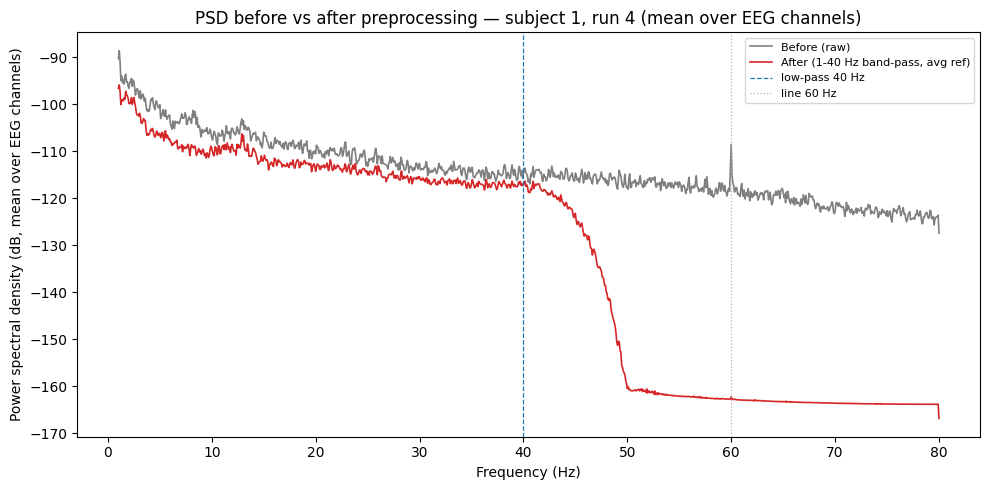

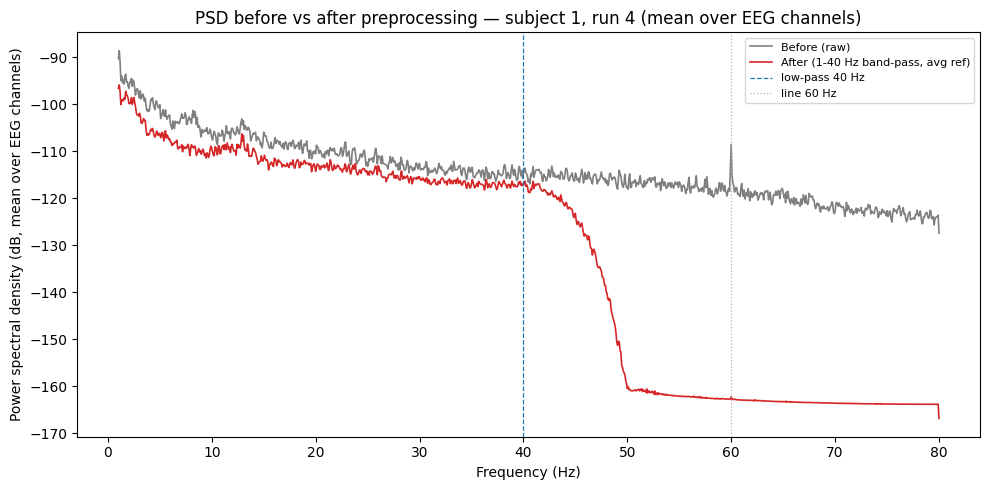

In [3]:
fig_ba = visualization.plot_filter_psd_comparison(
    raw_before, raw_after, fmin=1.0, fmax=80.0,
    title="PSD before vs after preprocessing — subject 1, run 4 (mean over EEG channels)",
)
visualization.save_figure(fig_ba, FIGURES_DIR / "preprocessing_before_after.png")
fig_ba

## 2 · Events and epochs

Annotation codes are mapped **by run type**. We first build a per-(subject, run,
condition) event-count table from the raw annotations using the pure
`eeg_lab.preprocessing` helpers, then create cue-locked epochs.

In [4]:
subject_runs = list(product(SUBJECTS, RUNS))
records = []
for subject, run in subject_runs:
    raw = data.load_run(subject, run, preload=False)
    records.append(
        {"subject": subject, "run": run, "descriptions": list(raw.annotations.description)}
    )

count_table = preprocessing.event_count_dataframe(records)
print("Per-(subject, run, condition) event counts:")
count_table

Per-(subject, run, condition) event counts:


,subject,run,role,condition,count
0,1,1,"Baseline, eyes open",rest (eyes open),1
1,1,2,"Baseline, eyes closed",rest (eyes closed),1
2,1,4,"Motor imagery, left vs right hand",rest,15
3,1,4,"Motor imagery, left vs right hand",left fist (imagined),8
4,1,4,"Motor imagery, left vs right hand",right fist (imagined),7
5,1,8,"Motor imagery, left vs right hand",rest,15
6,1,8,"Motor imagery, left vs right hand",left fist (imagined),8
7,1,8,"Motor imagery, left vs right hand",right fist (imagined),7
8,1,12,"Motor imagery, left vs right hand",rest,15
9,1,12,"Motor imagery, left vs right hand",left fist (imagined),7


In [5]:
# Totals per condition across the whole v1 slice, and a run x condition pivot.
totals = (
    count_table.groupby("condition")["count"].sum().sort_values(ascending=False)
)
print("Total events per condition (subjects 1–3, runs 1, 2, 4, 8, 12):")
print(totals.to_string())

pivot = (
    count_table.groupby(["run", "condition"])["count"].sum()
    .unstack("condition").fillna(0).astype(int)
)
print("\nEvent counts by run × condition (summed over subjects 1–3):")
pivot

Total events per condition (subjects 1–3, runs 1, 2, 4, 8, 12):
condition
rest                     135
left fist (imagined)      69
right fist (imagined)     66
rest (eyes closed)         3
rest (eyes open)           3

Event counts by run × condition (summed over subjects 1–3):


condition,left fist (imagined),rest,rest (eyes closed),rest (eyes open),right fist (imagined)
run,,,,,
1,0,0,0,3,0
2,0,0,3,0,0
4,23,45,0,0,22
8,23,45,0,0,22
12,23,45,0,0,22


### Cue-locked epochs

Epoch window: **tmin = −0.5 s, tmax = +4.0 s** about each cue onset, with
baseline correction over the pre-cue interval `(None, 0.0)`. The +4 s span
covers the ~4.1 s annotated motor-imagery task period; the 0.5 s pre-cue segment
is the baseline. Only motor-imagery runs (4, 8, 12) yield task epochs; the
baseline runs are a single continuous rest each and are used for PSD instead.

In [6]:
raw_mi = data.load_raw(1, [4])
preprocessing.apply_basic_preprocessing(raw_mi)
epochs = preprocessing.make_epochs(raw_mi, run=4)

print(f"Epoch window      : {epochs.tmin} to {epochs.tmax} s")
print(f"Conditions (event_id): {epochs.event_id}")
print(f"Epoch counts per condition:")
for cond in epochs.event_id:
    print(f"  {cond:<26}: {len(epochs[cond])}")
print(f"Total epochs       : {len(epochs)}")

Epoch window      : -0.5 to 4.0 s
Conditions (event_id): {'rest': 1, 'left fist (imagined)': 2, 'right fist (imagined)': 3}
Epoch counts per condition:
  rest                      : 14
  left fist (imagined)      : 8
  right fist (imagined)     : 7
Total epochs       : 29


### Example epochs

Condition-averaged, cue-locked traces on three central motor channels
(C3 / Cz / C4). This is a descriptive view of a small sample — not an
established evoked effect. With only ~7–8 trials per condition in one run, the
averages are noisy; the point is to show that epoching and condition labeling
work end to end.

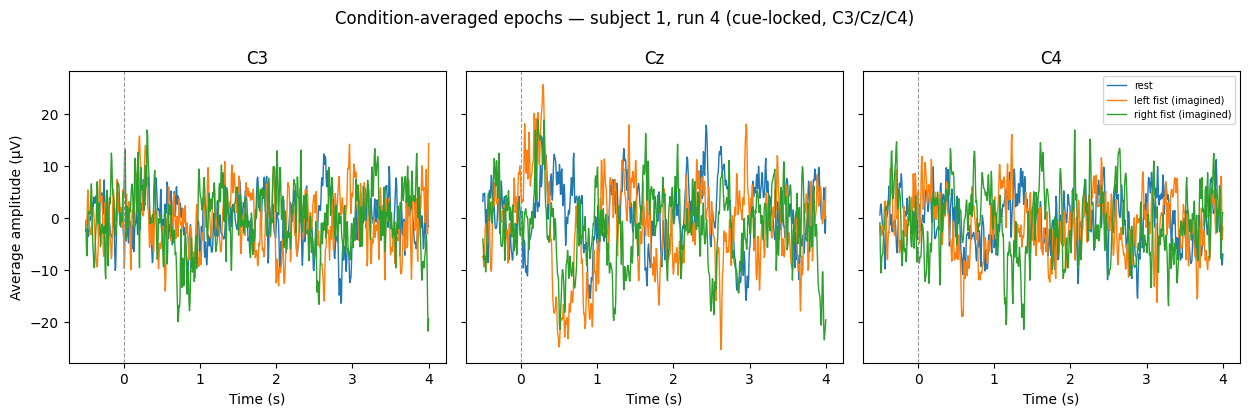

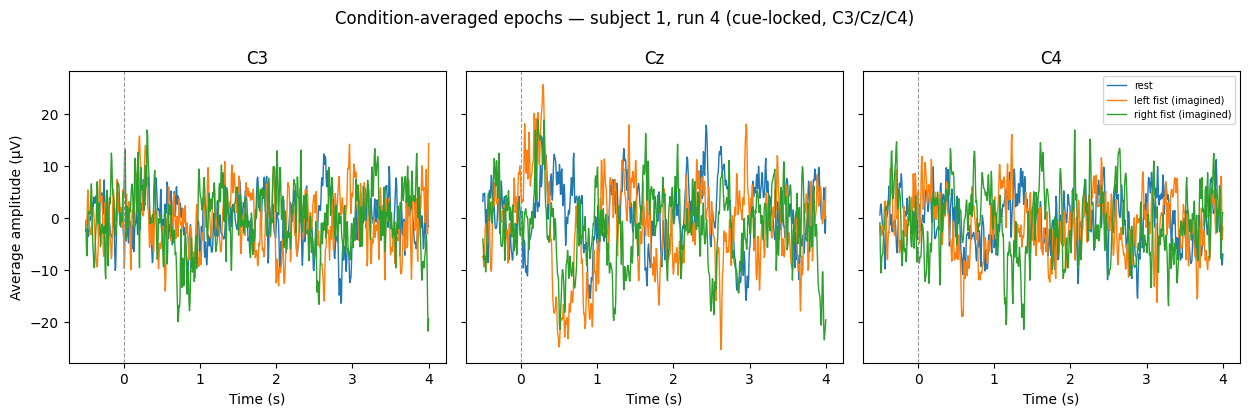

In [7]:
fig_ep = visualization.plot_epochs_overview(
    epochs, picks=("C3", "Cz", "C4"),
    title="Condition-averaged epochs — subject 1, run 4 (cue-locked, C3/Cz/C4)",
)
visualization.save_figure(fig_ep, FIGURES_DIR / "epochs_example.png")
fig_ep